### Dependencias

In [22]:
import pandas as pd
import os

import numpy as np

In [23]:
pd.set_option("display.max_colwidth", None)   
pd.set_option("display.width", None)          
pd.set_option("display.max_columns", None)    

In [24]:
files_path = "data/"

csv_files = sorted(
    filename
    for filename in os.listdir(files_path)
    if filename.lower().endswith(".csv")
)

csv_files

['olist_customers_dataset.csv',
 'olist_geolocation_dataset.csv',
 'olist_order_items_dataset.csv',
 'olist_order_payments_dataset.csv',
 'olist_order_reviews_dataset.csv',
 'olist_orders_dataset.csv',
 'olist_products_dataset.csv',
 'olist_sellers_dataset.csv',
 'product_category_name_translation.csv']

In [25]:
tables = {
    filename.removesuffix(".csv"): pd.read_csv(
        os.path.join(files_path, filename)
    )
    for filename in csv_files
}

tables.keys()

dict_keys(['olist_customers_dataset', 'olist_geolocation_dataset', 'olist_order_items_dataset', 'olist_order_payments_dataset', 'olist_order_reviews_dataset', 'olist_orders_dataset', 'olist_products_dataset', 'olist_sellers_dataset', 'product_category_name_translation'])

In [26]:
tables["olist_geolocation_dataset"]

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP
...,...,...,...,...,...
1000158,99950,-28.068639,-52.010705,tapejara,RS
1000159,99900,-27.877125,-52.224882,getulio vargas,RS
1000160,99950,-28.071855,-52.014716,tapejara,RS
1000161,99980,-28.388932,-51.846871,david canabarro,RS


In [27]:
tables['olist_customers_dataset']

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP
...,...,...,...,...,...
99436,17ddf5dd5d51696bb3d7c6291687be6f,1a29b476fee25c95fbafc67c5ac95cf8,3937,sao paulo,SP
99437,e7b71a9017aa05c9a7fd292d714858e8,d52a67c98be1cf6a5c84435bd38d095d,6764,taboao da serra,SP
99438,5e28dfe12db7fb50a4b2f691faecea5e,e9f50caf99f032f0bf3c55141f019d99,60115,fortaleza,CE
99439,56b18e2166679b8a959d72dd06da27f9,73c2643a0a458b49f58cea58833b192e,92120,canoas,RS


In [28]:
table_summary = pd.DataFrame([
    {
        "table": name,
        "rows": len(df),
        "columns": len(df.columns),
        "column_names": ", ".join(df.columns),
    }
    for name, df in tables.items()
]).sort_values("table").reset_index(drop=True)

table_summary

,table,rows,columns,column_names
0,olist_customers_dataset,99441,5,"customer_id, customer_unique_id, customer_zip_code_prefix, customer_city, customer_state"
1,olist_geolocation_dataset,1000163,5,"geolocation_zip_code_prefix, geolocation_lat, geolocation_lng, geolocation_city, geolocation_state"
2,olist_order_items_dataset,112650,7,"order_id, order_item_id, product_id, seller_id, shipping_limit_date, price, freight_value"
3,olist_order_payments_dataset,103886,5,"order_id, payment_sequential, payment_type, payment_installments, payment_value"
4,olist_order_reviews_dataset,99224,7,"review_id, order_id, review_score, review_comment_title, review_comment_message, review_creation_date, review_answer_timestamp"
5,olist_orders_dataset,99441,8,"order_id, customer_id, order_status, order_purchase_timestamp, order_approved_at, order_delivered_carrier_date, order_delivered_customer_date, order_estimated_delivery_date"
6,olist_products_dataset,32951,9,"product_id, product_category_name, product_name_lenght, product_description_lenght, product_photos_qty, product_weight_g, product_length_cm, product_height_cm, product_width_cm"
7,olist_sellers_dataset,3095,4,"seller_id, seller_zip_code_prefix, seller_city, seller_state"
8,product_category_name_translation,71,2,"product_category_name, product_category_name_english"


In [29]:
orders = tables["olist_orders_dataset"]

orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [30]:
eligible_orders = orders.loc[
    orders["order_status"].eq("delivered")
    & orders["order_delivered_customer_date"].notna()
    & orders["order_estimated_delivery_date"].notna()
].copy()

eligible_orders["late_days"] = (
    pd.to_datetime(eligible_orders["order_delivered_customer_date"])
    - pd.to_datetime(eligible_orders["order_estimated_delivery_date"])
).dt.days

eligible_orders["late"] = (eligible_orders["late_days"] > 0).astype("int8")

print(f"Eligible delivered orders: {len(eligible_orders):,}")
print(f"Late-order rate: {eligible_orders['late'].mean():.1%}")

eligible_orders[["order_id", "order_purchase_timestamp", "late_days", "late"]].head()

Eligible delivered orders: 96,470
Late-order rate: 6.8%


,order_id,order_purchase_timestamp,late_days,late
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-02 10:56:33,-8,0
1,53cdb2fc8bc7dce0b6741e2150273451,2018-07-24 20:41:37,-6,0
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-08 08:38:49,-18,0
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-11-18 19:28:06,-13,0
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-13 21:18:39,-10,0


In [31]:
eligible_orders['order_estimated_delivery_date']

0        2017-10-18 00:00:00
1        2018-08-13 00:00:00
2        2018-09-04 00:00:00
3        2017-12-15 00:00:00
4        2018-02-26 00:00:00
                ...         
99436    2017-03-28 00:00:00
99437    2018-03-02 00:00:00
99438    2017-09-27 00:00:00
99439    2018-02-15 00:00:00
99440    2018-04-03 00:00:00
Name: order_estimated_delivery_date, Length: 96470, dtype: object

In [32]:
actual = pd.to_datetime(eligible_orders["order_delivered_customer_date"])
estimated = pd.to_datetime(eligible_orders["order_estimated_delivery_date"])

eligible_orders["delay_days"] = (
    (actual - estimated).dt.total_seconds() / (24 * 60 * 60)
)

eligible_orders["late"] = (eligible_orders["delay_days"] > 0).astype("int8")

count    96470.000000
mean       -11.178126
std         10.184354
min       -146.016123
1%         -35.144500
25%        -16.244065
50%        -11.948102
75%         -6.389815
99%         18.939553
max        188.975081
Name: delay_days, dtype: float64
Delivered late: 8.1%
Delivered early: 91.9%
On time: 0.0%


C:\Users\adria\AppData\Local\Temp\ipykernel_17280\909355200.py:15: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


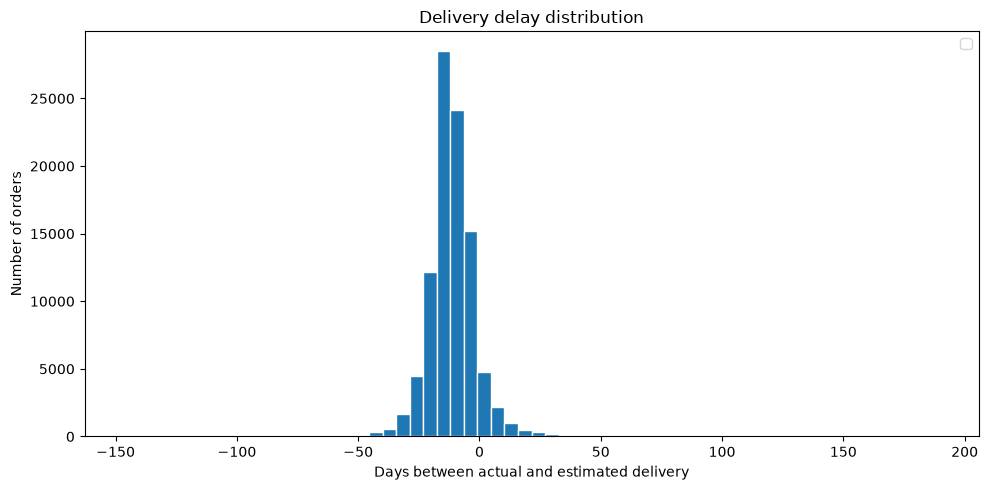

In [33]:
import matplotlib.pyplot as plt

delay = eligible_orders["delay_days"].dropna()

print(delay.describe(percentiles=[0.01, 0.25, 0.50, 0.75, 0.99]))
print(f"Delivered late: {(delay > 0).mean():.1%}")
print(f"Delivered early: {(delay < 0).mean():.1%}")
print(f"On time: {(delay == 0).mean():.1%}")

plt.figure(figsize=(10, 5))
plt.hist(delay, bins=60, edgecolor="white")
plt.xlabel("Days between actual and estimated delivery")
plt.ylabel("Number of orders")
plt.title("Delivery delay distribution")
plt.legend()
plt.tight_layout()
plt.show()

---
# Parte 2 · Modelo de predicción de entregas tardías

**Problema.** Una orden se considera *tardía* si se entrega después del día prometido al cliente. Queremos estimar, **al momento de la compra**, la probabilidad de retraso (0 = a tiempo, 1 = tardía) para actuar antes de que el cliente se queje.

**la fecha de entrega se considera con retraso solo si es posterior a la fecha prometida no en base al tiempo**.

In [34]:
eligible_orders = orders.loc[
    orders["order_status"].eq("delivered")
    & orders["order_delivered_customer_date"].notna()
    & orders["order_estimated_delivery_date"].notna()
].copy()
for c in ["order_purchase_timestamp","order_approved_at","order_delivered_carrier_date",
          "order_delivered_customer_date","order_estimated_delivery_date"]:
    eligible_orders[c] = pd.to_datetime(eligible_orders[c])
eligible_orders["late"] = (eligible_orders["order_delivered_customer_date"].dt.normalize()
                           > eligible_orders["order_estimated_delivery_date"].dt.normalize()).astype(int)
print(f"Órdenes elegibles: {len(eligible_orders):,} | Tasa de retraso: {eligible_orders['late'].mean():.1%}")

q = eligible_orders.groupby(eligible_orders["order_purchase_timestamp"].dt.to_period("Q"))["late"].agg(["mean","size"])
print(q.round(3))

Órdenes elegibles: 96,470 | Tasa de retraso: 6.8%
                           mean   size
order_purchase_timestamp              
2016Q3                    1.000      1
2016Q4                    0.008    266
2017Q1                    0.038   4949
2017Q2                    0.039   8983
2017Q3                    0.034  12215
2017Q4                    0.087  17279
2018Q1                    0.129  20627
2018Q2                    0.042  19643
2018Q3                    0.048  12507


## 1. Variables
Para evitar fuga de información no usamos nada posterior a la compra

In [35]:
def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

cust, sell = tables["olist_customers_dataset"], tables["olist_sellers_dataset"]
items = tables["olist_order_items_dataset"].copy()
items["shipping_limit_date"] = pd.to_datetime(items["shipping_limit_date"])
prod = tables["olist_products_dataset"].merge(tables["product_category_name_translation"], how="left", on="product_category_name")
prod["vol"] = prod.product_length_cm * prod.product_height_cm * prod.product_width_cm
pay = tables["olist_order_payments_dataset"]
geo = (tables["olist_geolocation_dataset"].groupby("geolocation_zip_code_prefix")[["geolocation_lat","geolocation_lng"]].mean())

items = (items.merge(prod[["product_id","product_category_name_english","product_weight_g","vol"]], on="product_id", how="left")
              .merge(sell, on="seller_id", how="left")
              .join(geo.add_prefix("s_"), on="seller_zip_code_prefix"))
agg = items.groupby("order_id").agg(
    n_items=("order_item_id","count"), n_sellers=("seller_id","nunique"), price=("price","sum"),
    freight=("freight_value","sum"), weight=("product_weight_g","sum"), vol=("vol","sum"),
    seller_state=("seller_state","first"), s_lat=("s_geolocation_lat","mean"), s_lng=("s_geolocation_lng","mean"),
    limit=("shipping_limit_date","min"), cat=("product_category_name_english","first")).reset_index()
pg = pay.groupby("order_id").agg(pay_type=("payment_type","first"), installments=("payment_installments","max")).reset_index()

df = (eligible_orders.merge(cust, on="customer_id", how="left").merge(agg, on="order_id", how="left")
        .merge(pg, on="order_id", how="left").join(geo.add_prefix("c_"), on="customer_zip_code_prefix"))
t = df["order_purchase_timestamp"]
df["dist_km"] = haversine(df.s_lat, df.s_lng, df.c_geolocation_lat, df.c_geolocation_lng)
df["promised_days"] = (df.order_estimated_delivery_date - t).dt.total_seconds()/86400
df["limit_days"] = (df["limit"] - t).dt.total_seconds()/86400
df["dow"], df["hour"], df["month"] = t.dt.dayofweek, t.dt.hour, t.dt.month
df["same_state"] = (df.customer_state == df.seller_state).astype(int)
df["freight_ratio"] = df.freight / (df.price + 1)
df["est_dow"] = df.order_estimated_delivery_date.dt.dayofweek
df = df.sort_values("order_purchase_timestamp").reset_index(drop=True)

CAT = ["customer_state","seller_state","cat","pay_type"]
NUM = ["n_items","n_sellers","price","freight","weight","vol","installments","dist_km","promised_days",
       "limit_days","dow","hour","month","same_state","freight_ratio","est_dow"]
for c in CAT: df[c] = df[c].fillna("NA").astype("category")
FEATS = NUM + CAT
print(df.shape)

(96470, 37)


## 2. Partición temporal (train / validación / test)
Para no mezclar datos futoros y pasados decidimos hacer la siguiente partición de los datos
- **Train:** hasta 31-dic-2017 · **Validación:** ene–mar 2018 · **Test:** abr–ago 2018 (el modelo final se reentrena con train+validación).

In [36]:
t = df["order_purchase_timestamp"]
train = df[t < "2018-01-01"]; valid = df[(t >= "2018-01-01") & (t < "2018-04-01")]; test = df[t >= "2018-04-01"]
fit = pd.concat([train, valid])
for n, x in dict(train=train, valid=valid, test=test).items():
    print(f"{n:6s} n={len(x):6,d}  tasa de retraso={x.late.mean():.2%}")

train  n=43,693  tasa de retraso=5.62%
valid  n=20,627  tasa de retraso=12.88%
test   n=32,150  tasa de retraso=4.42%


In [37]:
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss, precision_recall_curve
import lightgbm as lgb

def lin():
    ct = ColumnTransformer([("n", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUM),
                            ("c", OneHotEncoder(handle_unknown="ignore", min_frequency=50), CAT)])
    return make_pipeline(ct, LogisticRegression(max_iter=2000, class_weight="balanced", C=0.5))
def rf():
    ct = ColumnTransformer([("n", SimpleImputer(strategy="median"), NUM),
                            ("c", OneHotEncoder(handle_unknown="ignore", min_frequency=50), CAT)])
    return make_pipeline(ct, RandomForestClassifier(n_estimators=300, min_samples_leaf=20,
                         class_weight="balanced_subsample", n_jobs=-1, random_state=0))
def gbm():
    return lgb.LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=50,
                              subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=5,
                              random_state=0, verbose=-1)

def recall_at(y, p, k=0.10):
    n = int(len(y)*k); idx = np.argsort(-p)[:n]; return y[idx].sum()/y.sum(), y[idx].mean()

y = test.late.values
rows = {}
rows["Baseline 0 · Siempre 'a tiempo'"] = dict(PR_AUC=y.mean(), ROC_AUC=0.5, Recall_top10=0.10, Lift_top10=1.0, Brier=np.nan)
p_rule = test.dist_km.fillna(test.dist_km.median()).values
r, pr_ = recall_at(y, p_rule)
rows["Baseline 1 · Regla: más distancia = más riesgo"] = dict(PR_AUC=average_precision_score(y,p_rule), ROC_AUC=roc_auc_score(y,p_rule), Recall_top10=r, Lift_top10=pr_/y.mean(), Brier=np.nan)

preds = {}
for name, f in {"Regresión logística": lin, "Random Forest": rf, "LightGBM": gbm}.items():
    m = f().fit(fit[FEATS], fit.late); p = m.predict_proba(test[FEATS])[:,1]; preds[name] = (m, p)
    r, pr_ = recall_at(y, p)
    rows[name] = dict(PR_AUC=average_precision_score(y,p), ROC_AUC=roc_auc_score(y,p), Recall_top10=r, Lift_top10=pr_/y.mean(), Brier=brier_score_loss(y,p))
results = pd.DataFrame(rows).T.round(3)
results

,PR_AUC,ROC_AUC,Recall_top10,Lift_top10,Brier
Baseline 0 · Siempre 'a tiempo',0.044,0.500,0.100,1.000,NaN
Baseline 1 · Regla: más distancia = más riesgo,0.061,0.530,0.202,2.020,NaN
Regresión logística,0.107,0.729,0.279,2.787,0.242
Random Forest,0.093,0.690,0.254,2.540,0.113
LightGBM,0.109,0.727,0.273,2.730,0.041


Los tres modelos superan a los baselines. Regresión logística y LightGBM empatan pero vamos a usar **LightGBM** porque sus probabilidades están bien calibradas (Brier más bajo; la reg logistica usa class_weight y las infla).

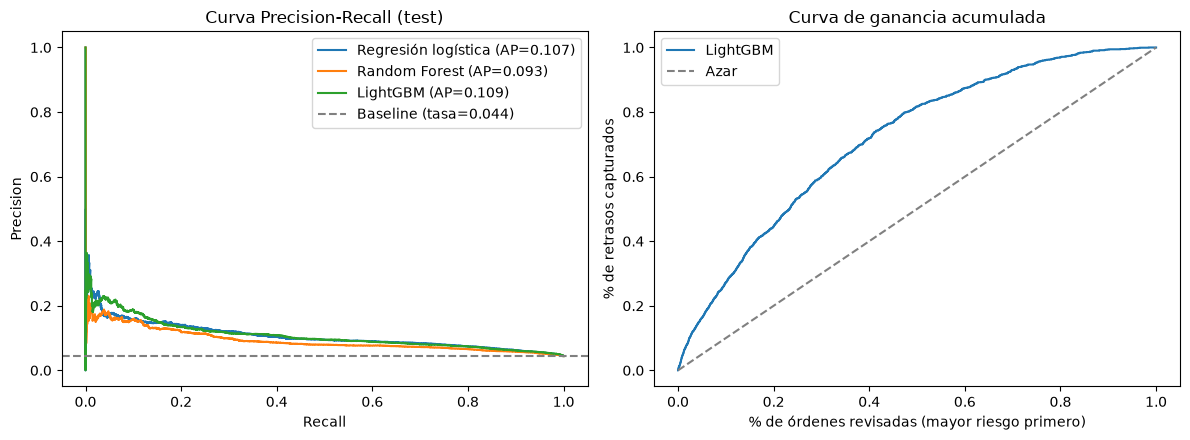

Probabilidad media predicha: 0.049 | tasa real en test: 0.044


In [38]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for n, (m, p) in preds.items():
    pr, rc, _ = precision_recall_curve(y, p); ax[0].plot(rc, pr, label=f"{n} (AP={average_precision_score(y,p):.3f})")
ax[0].axhline(y.mean(), color="gray", ls="--", label=f"Baseline (tasa={y.mean():.3f})")
ax[0].set_xlabel("Recall"); ax[0].set_ylabel("Precision"); ax[0].set_title("Curva Precision-Recall (test)"); ax[0].legend()
p = preds["LightGBM"][1]; o = np.argsort(-p); yy = y[o]
ax[1].plot(np.arange(1, len(yy)+1)/len(yy), np.cumsum(yy)/yy.sum(), label="LightGBM"); ax[1].plot([0,1],[0,1],"--",color="gray",label="Azar")
ax[1].set_xlabel("% de órdenes revisadas (mayor riesgo primero)"); ax[1].set_ylabel("% de retrasos capturados"); ax[1].set_title("Curva de ganancia acumulada"); ax[1].legend()
plt.tight_layout(); plt.show()
print("Probabilidad media predicha:", round(p.mean(),3), "| tasa real en test:", round(y.mean(),3))

## 4. Impacto en el negocio 
En el modelo marcamos el 10 % de órdenes con mayor riesgo de ser tardias y simulamos ajustando la fecha prometida a +3/+5/+7 días de estas ordenes. Con esto podriamos cambiar la inconformidad del cliente a la hora de calificar.

In [39]:
te = test[["order_id","late","order_delivered_customer_date","order_estimated_delivery_date"]].copy()
te["p"] = preds["LightGBM"][1]
te["delay"] = (te.order_delivered_customer_date.dt.normalize() - te.order_estimated_delivery_date.dt.normalize()).dt.days
flag = te.sort_values("p", ascending=False).head(int(len(te)*0.10))
caught = flag[flag.late == 1]
out = {"Órdenes en test": len(te), "Órdenes tardías (total)": int(te.late.sum()), "Órdenes marcadas (top 10%)": len(flag),
       "Tardías capturadas": len(caught), "% de tardías capturadas": round(len(caught)/te.late.sum(), 3)}
for X in (3, 5, 7):
    out[f"Rescatadas con +{X} días"] = int((caught.delay <= X).sum())
pd.Series(out)

Órdenes en test               32150.000
Órdenes tardías (total)        1421.000
Órdenes marcadas (top 10%)     3215.000
Tardías capturadas              388.000
% de tardías capturadas           0.273
Rescatadas con +3 días          113.000
Rescatadas con +5 días          174.000
Rescatadas con +7 días          240.000
dtype: float64

In [40]:
rev = pd.read_csv(os.path.join(files_path, "olist_order_reviews_dataset.csv")).sort_values("review_answer_timestamp").drop_duplicates("order_id", keep="last")
x = df[["order_id","late"]].merge(rev[["order_id","review_score"]], on="order_id")
print(x.groupby("late").review_score.agg(calificación_media="mean", órdenes="size").round(2))
print("\n% de reseñas de 1-2 estrellas:"); print(x.groupby("late").review_score.apply(lambda s: (s<=2).mean()).round(3))

      calificación_media  órdenes
late                             
0                   4.29    89443
1                   2.27     6381

% de reseñas de 1-2 estrellas:
late
0    0.093
1    0.624
Name: review_score, dtype: float64


## 5.modelo 2 (tras la entrega al transportista)
Con sólo datos de la compra el modelo ordena riesgo con poder moderado. Probamos un modelo en ese punto para dimensionar la mejora.

In [41]:
d2 = df.copy()
d2["approval_h"] = (d2.order_approved_at - d2.order_purchase_timestamp).dt.total_seconds()/3600
d2["handoff_vs_limit_d"] = (d2.order_delivered_carrier_date - d2["limit"]).dt.total_seconds()/86400
d2["handoff_d"] = (d2.order_delivered_carrier_date - d2.order_purchase_timestamp).dt.total_seconds()/86400
S2 = FEATS + ["approval_h","handoff_vs_limit_d","handoff_d"]
t2 = d2.order_purchase_timestamp; f2, te2 = d2[t2 < "2018-04-01"], d2[t2 >= "2018-04-01"]
m2 = gbm().fit(f2[S2], f2.late); p2 = m2.predict_proba(te2[S2])[:,1]; r2, pr2 = recall_at(te2.late.values, p2)
print(f"2ª etapa -> PR-AUC={average_precision_score(te2.late,p2):.3f} | ROC-AUC={roc_auc_score(te2.late,p2):.3f} | Recall@10%={r2:.1%} | Precision@10%={pr2:.1%}")

2ª etapa -> PR-AUC=0.340 | ROC-AUC=0.830 | Recall@10%=49.6% | Precision@10%=21.9%


### Conclusiones 
- El modelo al momento de compra detecta retrasos ~2.7 veces mejor que el azar en el 10 % de órdenes de mayor riesgo, pero no es perfecto (ROC-AUC ≈ 0.73).
- Probamos variables adicionales (historial de retraso del vendedor/ruta y carga reciente de la plataforma): empeoraron el test por cambios de régimen en el tiempo, así que no se incluyeron.